# **GameGazer – Insights into sales trends across platforms**

2.
**Research Question:** Can the sales of a video game world wide be predicted, through its platform, its genre, its publisher, and its regional sales success?

**Reason why it's Interesting:** The video game industry is a billion-dollar field in which it is important to predict the success of a game to the publishers and investors. Knowing what sells can be useful to studios in distributing their marketing budgets, making decisions like on which platforms to release the game and minimize the chance of losses in the event that an investment goes bad due to poor selling performance. Being a gamer myself, I wonder what the specifics of the popularity of some games in the world.

**Predictive aspect:** We would like to estimate the world sales i.e. The Global Sales of a  game by having other quantifiable parameters (platform, genre, regional sales, year of release, etc).

3.
**The population is:** Every video game that has ever been released globally since 1980. It consists of games on all platforms (Nintendo, PlayStation, Xbox, PC, etc.), and through all publishers.

4.
# **Variables:**

**Independent Variables:**

a. Platform - The platform the game was published on.

b. Genre - Genre of the game

c. Publisher - The corporation that has published the game.

d. NASales, EUSales, JPSales, OtherSales - sales per region.

e. Year - release year.

**Dependent Variables:**

a. Global Sales - Cumulative sales of all regions.

Confounding Variables: An external variable that can affect the both Independent and Dependent Variables, that might change the relationship.

**Possible confounders:**

a. Marketing Budget - The higher the marketing spend of the games, the more they are bound to sell doesn't matter of the platform or genre. Not always true but still affects.

b. Critical Reviews / Ratings - Games that have a high critic rating tend to sell better.

c. Popularity of Game Franchises - Customary franchises tend to stimulate more sales irrespective of the other circumstances.

We actually can't control these factors because they are not included in the dataset. If we could have access to this information I would have liked to add them to the analysis to make the predictions more accurate.

5.
# **Hypothesis**

**H0 (Null Hypothesis)** - There is no significant impact of game genre and platform on the global sales.

**H1 (Alternative Hypothesis)** - The game genre and platform play a major role in the global sales.

I hope and believe that the analysis will reveal that action and sports games on major platforms (like PS or Nintendo) tend to sell better in the world market.

6.
# **Data Collection Plan**

**Data Source:** An existing vgsales.xlsx dataset (obtained on Kaggle).

**Representativeness:** The sample provided in the dataset consists of games of different decades, platforms and genres which provide a fairly representative sample of the industry.

**Data Collection:** Data was compiled with different public sales databases and industry reports and presented to the general public on Kaggle.

**Data Quality Steps:** The following project will involve cleaning the years that are missing, outliers and standardization of the names of publishers/platforms.

7.
# **Dataset Details**

**Why it's interesting:** I myself am interested in the trend in the gaming industry and how data science could help us see the business of gaming. It is fun to analyse and predict the success of sales to developers.

**Columns include:**

a. Rank

b. Name

c. Platform

d. Year

e. Genre

f. Publisher

g. NASales,EUSales, JPSales, OtherSales

h. Global_Sales

**Source:** Kaggle Public Dataset: Sales in video games.

**Time Period:** Covering a period between 1980 and 2016.

Code Begins Here:

# **This line is most important to run for all imports !**

In [ ]:
import pandas as pd
from google.colab import drive
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Importing my dataset from google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Mounted the google drive
import pandas as pd
file_path = r'D:\Sakshaat\ALL PROJECTS AND CODES\2026 Projects\GameGazer\vgsales.xlsx' #Filepath to the dataset

In [ ]:
df = pd.read_excel(file_path) #Converting csv file into a dataframe
df.head() #Printing the first 5 rows


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


# **Project 2 Begins Here:**

**2. Getting the Preliminary Data**

In [ ]:
import numpy as np
from scipy import stats

df.head() #Checking if the data is correctly imported

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


**2.1 The shape of the data**

**2.2 Data types in the data**

**2.3 List of all column names**

**2.4 Unique elements in the data**

**2.5 Descriptive Statistics on the overall data**

In [ ]:
print("2.1 Shape of the dataset (rows, columns): ", df.shape)

2.1 Shape of the dataset (rows, columns):  (16598, 11)


In [ ]:
df.dtypes # 2.2

,0
Rank,int64
Name,object
Platform,object
Year,object
Genre,object
Publisher,object
NA_Sales,float64
EU_Sales,float64
JP_Sales,float64
Other_Sales,float64


In [ ]:
df.columns.tolist() # 2.3

['Rank',
 'Name',
 'Platform',
 'Year',
 'Genre',
 'Publisher',
 'NA_Sales',
 'EU_Sales',
 'JP_Sales',
 'Other_Sales',
 'Global_Sales']

In [ ]:
df.nunique() # 2.4

,0
Rank,16598
Name,11493
Platform,33
Year,40
Genre,14
Publisher,579
NA_Sales,409
EU_Sales,305
JP_Sales,244
Other_Sales,157


In [ ]:
df.describe(include='all') # 2.5

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16598,16598,16327.0,16598,16540,16598.000000,16598.000000,16598.000000,16598.000000,16596.000000
unique,NaN,11493,33,40.0,14,579,NaN,NaN,NaN,NaN,NaN
top,NaN,Need for Speed: Most Wanted,DS,2009.0,Action,Electronic Arts,NaN,NaN,NaN,NaN,NaN
freq,NaN,12,2163,1431.0,3316,1351,NaN,NaN,NaN,NaN,NaN
mean,8300.605254,NaN,NaN,NaN,NaN,NaN,0.264667,0.146659,0.077774,0.048070,0.537498
std,4791.853933,NaN,NaN,NaN,NaN,NaN,0.816683,0.505350,0.309292,0.188588,1.555113
min,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,NaN,NaN,NaN,NaN,NaN,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,NaN,NaN,NaN,NaN,NaN,0.240000,0.110000,0.040000,0.040000,0.470000


# **3. Looking for specific data needs for my project**

**3.1** This project uses only one dataset (vgsales.xlsx), so no merging or external linking is required.

**3.2** The dataset already contains rich information on sales across regions, publishers and platforms.

**3.3** My focus in this project (Project 2) is purely on cleaning, verifying, and restructuring the dataset for future analysis.

**Thus, no additional datasets are needed.**

# **4. Look for potential issues in the data**

**4.1 Duplicate Records:**

In [ ]:
# Detecting Duplicate Rows
duplicates = df[df.duplicated()]
print("Number of duplicate rows: ", duplicates.shape[0])

Number of duplicate rows:  0


**4.1** After inspecting the dataset, we found that there are no duplicate rows.

**This indicates each record in the dataset is unique.**

In [ ]:
# Detecting Missing Values
missing_values = df.isnull().sum()
print("Missing values in each column:\n", missing_values)
missing_rows = df[df.isnull().any(axis = 1)]
print(f"\n Total rows with missing values: {len(missing_rows)}")
if len(missing_rows) > 0:
  display(missing_rows.head())
else:
  print("No missing values found in the dataset.")

Missing values in each column:
 Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      2
dtype: int64

 Total rows with missing values: 309


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
179,180,Madden NFL 2004,PS2,NaN,Sports,Electronic Arts,4.26,0.26,0.01,0.71,5.23
377,378,FIFA Soccer 2004,PS2,NaN,Sports,Electronic Arts,0.59,2.36,0.04,0.51,3.49
431,432,LEGO Batman: The Videogame,Wii,NaN,Action,Warner Bros. Interactive Entertainment,1.86,1.02,0.00,0.29,3.17
470,471,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,NaN,1.57,1.02,0.00,0.41,3.00
607,608,Space Invaders,2600,NaN,Shooter,Atari,2.36,0.14,0.00,0.03,2.53


**4.2 a) Yes, there are missing values in the dataset.**

The table above shows the number of missing values in each column. Most columns are complete, but:

**Columns with missing values**
- **Year** has **271** missing entries
- **Publisher** has **58** missing entries
- **Global_Sales** has **2** missing entries

That is, before going ahead these missing values should be addressed.

**4.2 b) Type of Missing Data**
- The missing values are represented as NaN in pandas.

**4.2 c) Where are they?**
- Missing Year values indicate some games do not have a release year recorded.
- Missing Publisher values indicate some games do not have publisher information.
- Missing Global_Sales values likely indicates incomplete sales data.

**4.2 d) Are they expected?**
- **Partially expected:** In real-world datasets, missing Publisher or Year can happen if the data source didn't have complete records. For games that are very niche that they are not denoted.
- Missing Global_Sales is less ideal and might need to be handled (i.e either fill that space or drop that).

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  object 
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16596 non-null  float64
dtypes: float64(5), int64(1), object(5)
memory usage: 1.4+ MB


**4.3 Analysis of the above Output:-**

**The columns:-** Rank, Name, Platform, Genre, Publisher, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales have the correct data types as they should be.

- The observed type inconsistency is: The **Year** column is of type **object** instead of **numeric**.
- This suggests that there are non-numeric entries like **'NaN'** in the Year column as wee see in missing column head.

- This would ruin any analysis involving Year (like filtering by year, plotting trends) or give incorrect results unless the type is corrected.

- We will have to correct this and address this later during **Data Cleaning**.



**4.4 Finding any misspellings or mistypings**

**To Understand my Data more efficiently and effectively**
- **Categorical Columns:**
  - Game_Title
  - Platform_Name
  - Game_Genre
  - Publisher_Name

- **Numerical_Columns:**
  - Rank_Global
  - Release_Year
  - NA_Sales_Millions
  - EU_Sales_Millions
  - JP_Sales_Millions
  - Other_Sales_Millions
  - Global_Sales_Millions


In [ ]:
categorical_columns = df.select_dtypes(include = ['object']).columns
print("Checking unique values for categorical columns: \n")
for col in categorical_columns:
  unique_col_values = df[col].unique()
  if len(unique_col_values) <= 20:
    print(f"\nColumn: {col}")
    print(unique_col_values)

print("\n Looking for inconsistencies like 'Action' vs 'action' or spelling differences.")

Checking unique values for categorical columns: 


Column: Genre
['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy'
 'Sony Computer Entertainment' 'Idea Factory']

 Looking for inconsistencies like 'Action' vs 'action' or spelling differences.


**4.4 Categorical columns with 20 or fewer unique values.**

In the 'Genre' column, most values are consistent and properly capitalized. However, 'Platform' maybe misplaced, and 'Sony Computer Entertainment' and 'Idea Factory' are publishers, not genres.

**Other categorical columns showed no obvious inconsistencies.**

**4.5 Any weird outliers (using Z-score)**

In [ ]:
numeric_df = df.select_dtypes(include=[np.number])
z_scores = np.abs(stats.zscore(numeric_df))
threshold = 2
outliers = (z_scores > threshold).any(axis=1)

print(f"Total potential outliers detected: {outliers.sum()}")

if outliers.sum() > 0:
  display(df[outliers].head())
else:
  print("No significant outliers detected using Z-score method.")

Total potential outliers detected: 830


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


**4.5 High values are flagged by z-score but are real, so I won't remove them coz they are actual real data values. They represent valid and top-selling games.**

# **5. Reorganization: Doing reorganization and Column renaming for improved clarity and consistency.**

In [ ]:
print("Original Columns: ")
print(df.columns.tolist())

df.rename(columns = {
    'Rank': 'Rank_Global',
    'Name': 'Game_Title',
    'Platform': 'Platform_Name',
    'Year': 'Release_Year',
    'Genre': 'Game_Genre',
    'Publisher': 'Publisher_Name',
    'NA_Sales': 'NA_Sales_Millions',
    'EU_Sales': 'EU_Sales_Millions',
    'JP_Sales': 'JP_Sales_Millions',
    'Other_Sales': 'Other_Sales_Millions',
    'Global_Sales': 'Global_Sales_Millions'
}, inplace = True)

print("\n New Column Names:")
print(df.columns.tolist())

Original Columns: 
['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

 New Column Names:
['Rank_Global', 'Game_Title', 'Platform_Name', 'Release_Year', 'Game_Genre', 'Publisher_Name', 'NA_Sales_Millions', 'EU_Sales_Millions', 'JP_Sales_Millions', 'Other_Sales_Millions', 'Global_Sales_Millions']


In [ ]:
df.head() # To check if the column names were changed properly

,Rank_Global,Game_Title,Platform_Name,Release_Year,Game_Genre,Publisher_Name,NA_Sales_Millions,EU_Sales_Millions,JP_Sales_Millions,Other_Sales_Millions,Global_Sales_Millions
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


**No column reordering was strictly required since the current order already flows logically.**

# **6. Developing a detailed plan:-**

After exploring the dataset, the following issues need to be addressed systematically:

**6.1. Missing Values:**

- **Columns Affected:** 'Release_Year', 'Publisher_Name', 'Global_Sales_Millions'.
- **Planned approach:**
  - For Release Year, fill missing values using the median of the valid entries, since the data is numeric but non-linear across time.
  - For Publisher_Name, impute with the mode.
  - I am going to keep the Release_Year and Publisher_Name only if needed for secondary analysis, not for the main hypothesis test.
  - For 'Global_Sales_Millions', If missing drop those rows, since sales is the outcome variable.

**6.2. Outlier Handling:**
- **Retain all outliers** in Global_Sales_Millions unless they are clear data entry errors (e.g., negative sales) as sales in center to my hypothesis.

- **Now do final checks if all missing values are removed.**

# **7. Cleaning Data Begins Here:**

In [ ]:
# Checked this because got error in doing Handling Missing values so had to.
print(df['Release_Year'].dtype)
print(df['Release_Year'].unique())

object
[2006 1985 2008 2009 1996 1989 1984 2005 1999 2007 2010 2013 2004 1990
 1988 2002 2001 2011 1998 2015 2012 2014 1992 1997 1993 1994 1982 2003
 1986 2000 nan 1995 2016 1991 1981 1987 1980 1983 2020 'Adventure' 2017]


In [ ]:
df['Release_Year'] = pd.to_numeric(df['Release_Year'], errors = 'coerce') # Adventure was coming as an error so had to remove that

In [ ]:
# Handling Missing Values
# For Release_Year, imputing with median
median_year = df['Release_Year'].median()
df['Release_Year'] = df['Release_Year'].fillna(median_year).astype(int)
# For Publisher_Name, imputing with mode
mode_publisher = df['Publisher_Name'].mode()[0]
df['Publisher_Name'] = df['Publisher_Name'].fillna(mode_publisher)
# For Global_Sales_Millions, drop rows with missing sales coz its a outcome variable
df = df.dropna(subset = ['Global_Sales_Millions'])
# Converting Release_Year to integer type after imputation
df.loc[:, 'Release_Year'] = df['Release_Year'].astype(int)
# Converting Global_Sales_Millions to numeric
df.loc[:, 'Global_Sales_Millions'] = pd.to_numeric(df['Global_Sales_Millions'], errors = 'coerce')
# Drop rows with non-numeric or negative sales values as data errors
df = df[df['Global_Sales_Millions'] >= 0].dropna(subset = ['Global_Sales_Millions'])

# Final Checks
print("Missing values after cleaning: ")
print(df[['Release_Year', 'Publisher_Name', 'Global_Sales_Millions']].isnull().sum())

print("Final dataset shape after cleaning: ", df.shape)


Missing values after cleaning: 
Release_Year             0
Publisher_Name           0
Global_Sales_Millions    0
dtype: int64
Final dataset shape after cleaning:  (16596, 11)


# **8. Saving the cleaned data to a new file.**

In [ ]:
cleaned_file_path = r'D:\Sakshaat\ALL PROJECTS AND CODES\2026 Projects\GameGazer\vgsales_cleaned.xlsx'
df.to_excel(cleaned_file_path, index = False)

print(f"Cleaned dataset saved to {cleaned_file_path}")

Cleaned dataset saved to /content/drive/MyDrive/602 - Data Science/vgsales_cleaned.xlsx


# **9. Importing Cleaned data file**

In [ ]:
df_cleaned = pd.read_excel(cleaned_file_path)
df_cleaned.head()

,Rank_Global,Game_Title,Platform_Name,Release_Year,Game_Genre,Publisher_Name,NA_Sales_Millions,EU_Sales_Millions,JP_Sales_Millions,Other_Sales_Millions,Global_Sales_Millions
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [ ]:
#Checking for missing values in the cleaned excel
missing_values = df_cleaned.isnull().sum()
print("Missing Values in the cleaned Excel Dataset: ")
print(missing_values)

Missing Values in the cleaned Excel Dataset: 
Rank_Global              0
Game_Title               0
Platform_Name            0
Release_Year             0
Game_Genre               0
Publisher_Name           0
NA_Sales_Millions        0
EU_Sales_Millions        0
JP_Sales_Millions        0
Other_Sales_Millions     0
Global_Sales_Millions    0
dtype: int64


# **10. Display**
- **The first 5 data entries from the cleaned data file.**
- **The last 5 data entries from the cleaned data file.**

In [ ]:
# Displaying First 5 entries
print("First 5 entries: ")
df_cleaned.head()

First 5 entries: 


,Rank_Global,Game_Title,Platform_Name,Release_Year,Game_Genre,Publisher_Name,NA_Sales_Millions,EU_Sales_Millions,JP_Sales_Millions,Other_Sales_Millions,Global_Sales_Millions
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [ ]:
# Displaying the Last 5 entries
print("\nLast 5 entries: ")
df_cleaned.tail()


Last 5 entries: 


,Rank_Global,Game_Title,Platform_Name,Release_Year,Game_Genre,Publisher_Name,NA_Sales_Millions,EU_Sales_Millions,JP_Sales_Millions,Other_Sales_Millions,Global_Sales_Millions
16591,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.0,0.0,0.01
16592,16597,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.0,0.0,0.01
16593,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.0,0.0,0.01
16594,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.0,0.0,0.01
16595,16600,Spirits & Spells,GBA,2003,Platform,Wanadoo,0.01,0.00,0.0,0.0,0.01


# **Project 2 ends here!**

# **Project 3 begins here:-**

In [ ]:
cleaned_file_path = r'D:\Sakshaat\ALL PROJECTS AND CODES\2026 Projects\GameGazer\vgsales_cleaned.xlsx'
df = pd.read_excel(cleaned_file_path)
df.head()

,Rank_Global,Game_Title,Platform_Name,Release_Year,Game_Genre,Publisher_Name,NA_Sales_Millions,EU_Sales_Millions,JP_Sales_Millions,Other_Sales_Millions,Global_Sales_Millions
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


### **2. Initial Thoughts:**

Before conducting detailed analysis, it is important to reflect on the suitability of the dataset. The dataset we have contains video game sales data globally, spanning from 1980 through 2016. It includes important attributes such as the platform each game was released on, the genre, its publisher, and detailed sales figures for different world regions as well as total global sales.

This dataset appears well-suited for our objective of predicting worldwide sales of video games based on various influential factors. It encompasses a broad selection of games released across diverse platforms, genres, and publishers, which helps ensure that any observed trends or predictive models will have general applicability within the gaming industry. Because the dataset was previously cleaned to handle missing values, unify variables, and remove duplicates, its quality and reliability are high, making it a solid foundation for further exploration.

**Before proceeding we can ask some questions:-**

*   Are there still any data quality issues, such as subtle inconsistencies or outliers, that might affect analysis outcomes?
*   Which platforms and genres contribute most substantially to global sales? Are some regions more reflective of global trends than others?
*   What is the relationship between regional sales? Do strong sales in one region predict broader global success?
*   How have sales evolved over time, and how might the timing of a game's release on certain platforms impact its success?
*   Are there clusters or patterns among publishers that influence sales?
*   Do factual observations support or contradict the working hypothesis that genre and platform significantly influence global sales?







### **3. Exploring characteristics of the data**



In [ ]:
# Checking dataset shape
print(f"Dataset Shape: {df.shape}")

# Verifying what each row represents
print("Each row corresponds to a unique video game release with associated sales and metadata.")

# Listing column names to understand available features
print("Dataset Columns:")
print(df.columns.tolist())

# Checking for duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

# Remove duplicates if any
if duplicate_count > 0:
  df.drop_duplicates(inplace = True)
  print("Duplicates removed.")
else:
  print("No duplicates found.")

Dataset Shape: (16596, 11)
Each row corresponds to a unique video game release with associated sales and metadata.
Dataset Columns:
['Rank_Global', 'Game_Title', 'Platform_Name', 'Release_Year', 'Game_Genre', 'Publisher_Name', 'NA_Sales_Millions', 'EU_Sales_Millions', 'JP_Sales_Millions', 'Other_Sales_Millions', 'Global_Sales_Millions']
Number of duplicate rows: 0
No duplicates found.


1. The dataset contains **16596 rows and 11 columns**. This means there are 16596 individual game records, each described by 11 features or variables.

2. Each row represents a unique video game entry.

3. **Columns:-**

'Rank_Global',

'Game_Title',

'Platform_Name',

'Release_Year',

'Game_Genre',

'Publisher_Name',

'NA_Sales_Millions',

'EU_Sales_Millions',

'JP_Sales_Millions',

'Other_Sales_Millions',

'Global_Sales_Millions'

4. **No duplicate rows** were found in the dataset.

5. Duplicates were checked using the pandas DataFrame **duplicated()** function which scans for fully identical rows. The count returned was zero, indicating uniqueness of all records.

6. If duplicates were present, they would need to be removed to avoid bias and redundancy in analysis. This would be done by dropping duplicate rows using **drop_duplicates()**. Additionally, if duplicates differ due to data entry errors, further investigation and data cleaning would be required.

### **4. Additional Data Transformation**


In [ ]:
print("Data types by column: ")
print(df.dtypes)

df['Platform_Code'] = df['Platform_Name'].astype('category').cat.codes
df['Genre_Code'] = df['Game_Genre'].astype('category').cat.codes
df['Publisher_Code'] = df['Publisher_Name'].astype('category').cat.codes

df.head()

Data types by column: 
Rank_Global                int64
Game_Title                object
Platform_Name             object
Release_Year               int64
Game_Genre                object
Publisher_Name            object
NA_Sales_Millions        float64
EU_Sales_Millions        float64
JP_Sales_Millions        float64
Other_Sales_Millions     float64
Global_Sales_Millions    float64
dtype: object


,Rank_Global,Game_Title,Platform_Name,Release_Year,Game_Genre,Publisher_Name,NA_Sales_Millions,EU_Sales_Millions,JP_Sales_Millions,Other_Sales_Millions,Global_Sales_Millions,Platform_Code,Genre_Code,Publisher_Code
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,26,10,359
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,11,4,359
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,26,6,359
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,26,10,359
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,5,7,359


In [ ]:
encoded_file_path = r'D:\Sakshaat\ALL PROJECTS AND CODES\2026 Projects\GameGazer\vgsales_encoded.xlsx'
df.to_excel(encoded_file_path, index = False)

print(f"Encoded dataset saved to {encoded_file_path}")

Encoded dataset saved to /content/drive/MyDrive/602 - Data Science/vgsales_encoded.xlsx


In [ ]:
df.head()

,Rank_Global,Game_Title,Platform_Name,Release_Year,Game_Genre,Publisher_Name,NA_Sales_Millions,EU_Sales_Millions,JP_Sales_Millions,Other_Sales_Millions,Global_Sales_Millions,Platform_Code,Genre_Code,Publisher_Code,Decade,Log_Global_Sales,Log_NA_Sales,Log_EU_Sales,Log_JP_Sales,Log_Other_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,26,10,359,2000,4.427717,3.749269,3.401864,1.562346,2.247072
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,11,4,359,1980,3.719409,3.403860,1.521699,2.055405,0.570980
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,26,6,359,2000,3.606041,2.824351,2.630449,1.566530,1.460938
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,26,10,359,2000,3.526361,2.818398,2.485740,1.453953,1.376244
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,5,7,359,1990,3.477232,2.507157,2.291524,2.417698,0.693147


In our dataset, columns like sales figures and year are numeric, while columns such as Platform, Genre and Publisher are categorical strings. Since, many machine learning models and numeric computations require numerical inputs, it is necessary to encode categrical variables into numeric codes.

The code converts the categorical columns 'Platform_Name', 'Game_Genre' and 'Publisher_Name' into numeric codes using pandas' category data type and .cat.codes property. This transformation retains the unique categories but maps them to integer codes, allowing algorithms to process them efficiently.

By displaying the transformed dataframe with the new numeric code columns, we verify that the encoding has been applied correctly while retaining the original features for reference.

**Applying Log Transformations:-**

In [ ]:
df['Log_Global_Sales'] = np.log1p(df['Global_Sales_Millions'])
df['Log_NA_Sales'] = np.log1p(df['NA_Sales_Millions'])
df['Log_EU_Sales'] = np.log1p(df['EU_Sales_Millions'])
df['Log_JP_Sales'] = np.log1p(df['JP_Sales_Millions'])
df['Log_Other_Sales'] = np.log1p(df['Other_Sales_Millions'])

Before Log transformation: 
       Global_Sales_Millions
count           16596.000000
mean                0.537498
std                 1.555113
min                 0.010000
25%                 0.060000
50%                 0.170000
75%                 0.470000
max                82.740000
After Log transformation: 
       Log_Global_Sales
count      16596.000000
mean           0.306540
std            0.396043
min            0.009950
25%            0.058269
50%            0.157004
75%            0.385262
max            4.427717


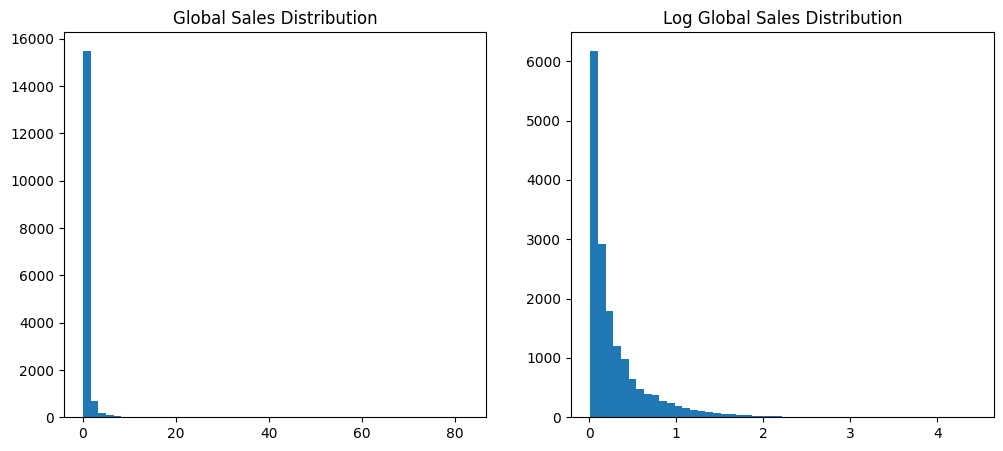

In [ ]:
print("Before Log transformation: ")
print(df[['Global_Sales_Millions']].describe())

print("After Log transformation: ")
print(df[['Log_Global_Sales']].describe())

plt.figure(figsize = (12, 5))
plt.subplot(1, 2, 1)
plt.hist(df['Global_Sales_Millions'], bins = 50)
plt.title('Global Sales Distribution')

plt.subplot(1, 2, 2)
plt.hist(df['Log_Global_Sales'], bins = 50)
plt.title('Log Global Sales Distribution')

plt.show()

Visualized after log transformations.

All values used ahead are of Log Transformations for better visualization.

5. **Explore every variable in the dataset individually**

Summary statistics for numerical data: 
        Rank_Global  Release_Year  NA_Sales_Millions  EU_Sales_Millions  JP_Sales_Millions  Other_Sales_Millions  Global_Sales_Millions  Platform_Code    Genre_Code  Publisher_Code        Decade  Log_Global_Sales  Log_NA_Sales  Log_EU_Sales  Log_JP_Sales  Log_Other_Sales
count  16596.000000  16596.000000       16596.000000       16596.000000       16596.000000          16596.000000           16596.000000   16596.000000  16596.000000    16596.000000  16596.000000      16596.000000  16596.000000  16596.000000  16596.000000     16596.000000
mean    8300.091046   2006.415883           0.264699           0.146670           0.077784              0.048069               0.537498      15.797722      4.928597      293.058990   2001.787178          0.306540      0.175316      0.103726      0.056887         0.040012
std     4791.901813      5.781966           0.816727           0.505379           0.309309              0.188599               1.555113       8.

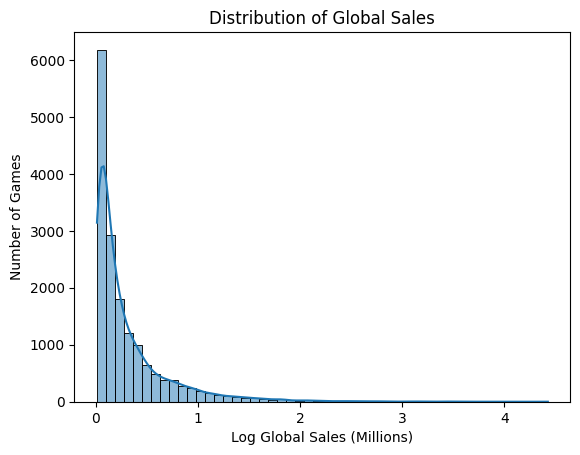

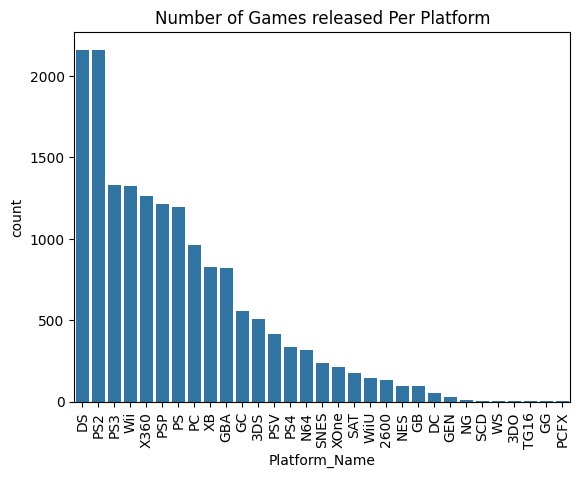

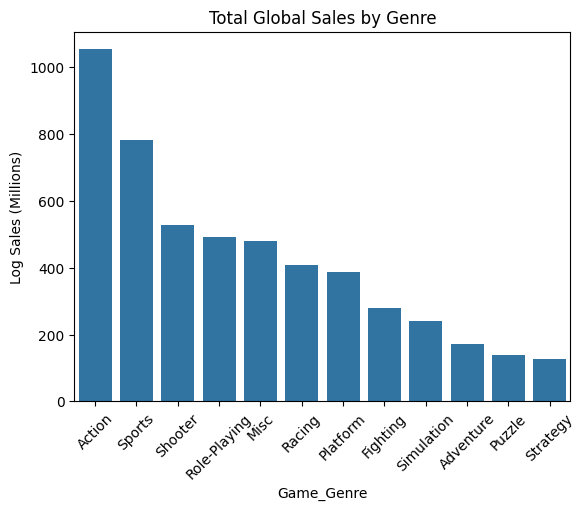

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 300)
print("Summary statistics for numerical data: ")
print(df.describe())

# Frequency counts for key categorical columns
for col in ['Platform_Name', 'Game_Genre', 'Publisher_Name']:
  print(f"\n Value counts for {col}:")
  print(df[col].value_counts())

# Distribution of global sales
plt.figure()
sns.histplot(df['Log_Global_Sales'], bins = 50, kde = True)
plt.title('Distribution of Global Sales')
plt.xlabel('Log Global Sales (Millions)')
plt.ylabel('Number of Games')
plt.show()

print("\n")

# Number of games released per platform
plt.figure()
sns.countplot(x = 'Platform_Name', data = df, order = df['Platform_Name'].value_counts().index)
plt.xticks(rotation = 90)
plt.title('Number of Games released Per Platform')
plt.show()

print("\n")

# Total sales by genre visualization
genre_sales = df.groupby('Game_Genre')['Log_Global_Sales'].sum().sort_values(ascending = False)
plt.figure()
sns.barplot(x = genre_sales.index, y = genre_sales.values)
plt.xticks(rotation = 45)
plt.title('Total Global Sales by Genre')
plt.ylabel('Log Sales (Millions)')
plt.show()

### **5. Explore every variable in the dataset**

**Q.** What is the variables datatype? What units are the variable measured in, and how do you know the units? What does the variable represent?

**Answer:-** The dataset contains a mixture of numerical and categorical variables. Numerical variables such as sales figures (Global_Sales_Millions, NA_Sales_Millions, EU_Sales_Millions, JP_Sales_Millions, Other_Sales_Millions) and Release_Year are represented as numeric dtaatypes (floats or integers). Sales variables are measured in millions of units sold, as inferred from the column names and dataset documentation. The Release_Year variable is measured in calendar years.

Categorical variables like Platform_Name, Game_Genre, and Publisher_Name are stored as object/string datatypes representing game platform, genre and publisher respectively. These categorical variables are transformed into numeric codes for computational convenience but originally represent discrete labels without units.

**Q.** Any transformations/manipulations needed to better analyze the variable?

**Answer:-** Most variables are in a good shape for analysis with appropriate datatypes andunits. The numerical sales figures are measured in millions and do not require unit conversion. Categorical variables such as platform, genre, and publisher have been encoded into numeric category codes to facilitate modeling and analysis. Release year was converted to integers and missing values handles. The sales data exhibits skewnwss, so logarithmic tranformation may be applied later to normalize the distributions for modeling. String variables were cleaned for consistency to avoid category mismatches. Overall, minimal additional transformations were needed beyond encoding and potential log scaling of sales variables to enhance analysis quality.

**Q.** Is this different from what you initially thought in step 5? Any missing data or extreme outliers? How do you know if there are or not? For any not already addressed in Pre-Processing: How will you handle them?

**Answer:-** There is no significant difference between the actual data characteristics and what was anticipated at the start of the analysis. They align with the initial expectations. Missing data and duplicates were addressed during preprocessing, currently there are no missing or duplicate values. Extreme outliers, particularly in sales data, exist but represent valid blockbuster game sales rather than data errors, so they have been retained. Since, the dataset is clean and outliers are meaningful, no further handling for missing or extreme values is necessary.

**Q.** What are the descriptive/summary statistics for the variable? What is the distribution of the variable’s values? What are the frequencies of values? Explain what you are seeing (or not seeing) in the visuals.

**Answer:-** The descriptive statistics provided above offer a detailed summary of numerical variables in the dataset. The statistics show that sales values, measured in millions, have a skewed distribution with most games selling relatively few copies and a small number of blockbusters selling tens of millions. The release years span from 1980 to 2020. Frequency counts reveal that platforms like DS and PS2 have the highest number of game releases, while genres such as Action and Sports dominate in total sales volume. Visualisations support these findings, with histograms displaying the sharp skew in sales and bar charts highlighting the dominance of popular platforms and genres. This blend of descriptive statistics and visuals provides a clear picture of the dataset's structure and market trends.



### **6. Exploring Relationships Between Variables**

Correlation analysis shows the degree to which sales in different regions and global sales are related. Time series scatter plots illustrate how sales have evolved across platforms over years. Boxplots reveal variation and outliers in sales by genre, highlighting which genres perform better or show more variability.

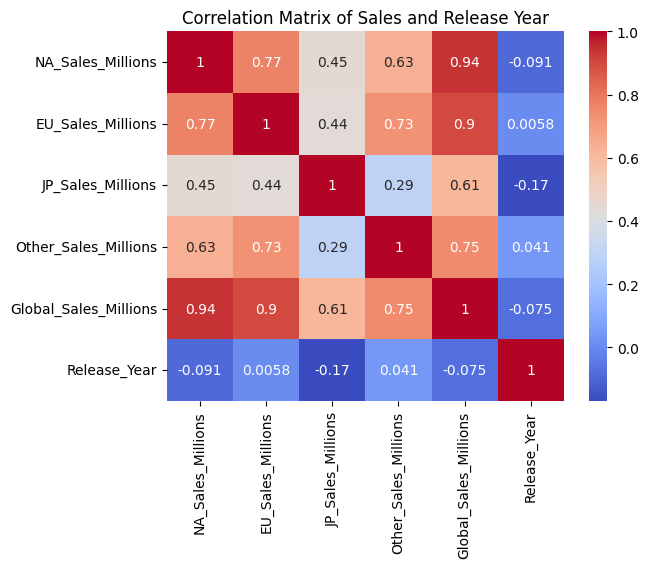

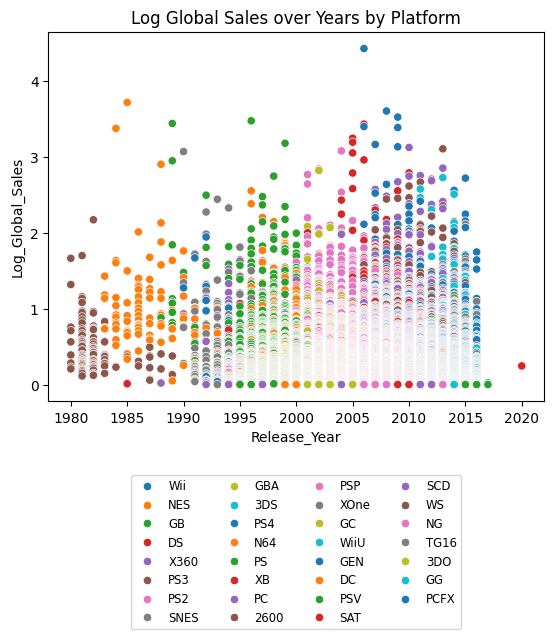

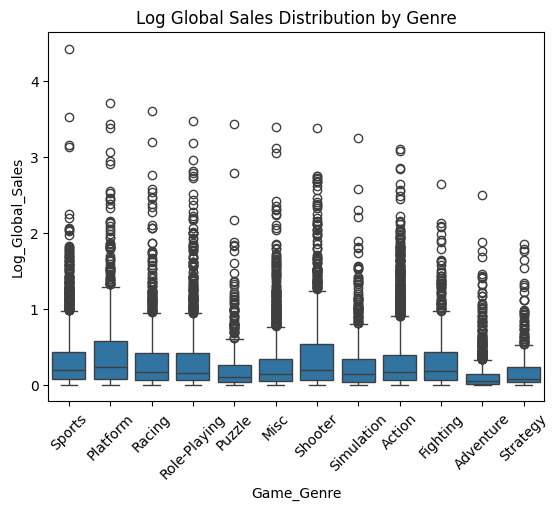

In [ ]:
# Correlation heatmap among numerical sales and columns and year
plt.figure()
sns.heatmap(df[['NA_Sales_Millions', 'EU_Sales_Millions', 'JP_Sales_Millions', 'Other_Sales_Millions', 'Global_Sales_Millions', 'Release_Year']].corr(), annot = True, cmap = 'coolwarm')
plt.title('Correlation Matrix of Sales and Release Year')
plt.show()

print("\n")

# Sales overtime with platforms
plt.figure()
sns.scatterplot(data = df, x = 'Release_Year', y = 'Log_Global_Sales', hue = 'Platform_Name', palette = 'tab10', legend  = 'full')
plt.title('Log Global Sales over Years by Platform')
plt.legend(bbox_to_anchor = (0.5, -0.2), loc = 'upper center', ncol = 4, borderaxespad = 0, fontsize = 'small')
plt.show()

print("\n")

#Boxplot to see sales distribution across genres
plt.figure()
sns.boxplot(x = 'Game_Genre', y = 'Log_Global_Sales', data = df)
plt.xticks(rotation = 45)
plt.title('Log Global Sales Distribution by Genre')
plt.show()

**Relationship Summary:**
*   There is a clear dependency of global sales on genre, platform and release year. Sales figures are dependent of these variables. That is, they are influenced by which platform and when a game was released, as well as the genre.
*   Regional sales variables show strong positive correlations with each other and with global sales. For example, as seen in the correlation maatrix , NA_Sales_Millions and Global_Sales_Millions are highly correlated (r = 0.94), meaning success in North America powerfully boosts global totals and trends.

**Event Frequencies:**
*   High-sales outliers exist with nearly all genres, but some genres (Action, Sports, Shooter) more frequently achieve higher sales, as seen in the boxplot of 'Global Sales Distribution by Genre'.
*   Event frequency is also evident in the scatterplot over years, certain years and platforms cluster with higher sales, e.g. the Wii in the mid-to-late 2000s.

**Periodicity/Seasonality:**
*   The scatterplot 'Global Sales over Years by Platform' suggests peaks around major console launches (mid - 2000s for Wii, Xbox 360, PS3/PS2).
*   Sales drop-off is observable for releases in later years (2015 onward), indicating market saturation or the effect of shifting industry trends. **My personal analogy is that just before lockdown there was a crazy wave of Adventure and Story-mode games hitting.**

**Correlations:**
*   The heatmap shows strong correlations among different regional sales, and each with global sales (especially NA and EU regions).
*   Release year is weakly negatively correlated with sales, shwoing that newer releases do not necessarily guarantee higher sales.

**Pairwise Relationships:**
*   The genre boxplot shows that while most games in every genre sell under 5 million units, some outliers in every category exceed 20 or even 80 million copies, meaning even niche genres can produce major hits.
*   Scatterplots show platform specific successes (e.g. Wii games reaching very high sales in specific years).

**Visual Insights:**
*   The boxplot by genre visually confirms that certain genres are more likely to produce high-selling games, but variability exists within every groups.
*   The correlation matrix visually emphasizes the strong dependence of global sales on regional sales, especially NA and EU.
*   The scatterplot by platform and year shows that platform launches and popularity periods correspond with spikes in sales.




# **Let's test Simpson's Paradox below:**

Simpson's paradox is a statistical phenomenon where a trend that appears in different groups of data disappears or reverses when the groups are combined.

**Test 1:- Sales Trends by Genre Across Decades**

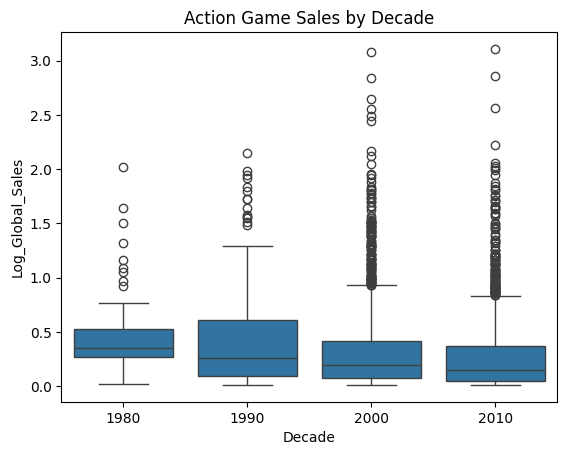

In [ ]:
df['Decade'] = (df['Release_Year'] // 10) * 10

# Action Genre across decades
plt.figure()
sns.boxplot(x = 'Decade', y = 'Log_Global_Sales', data = df[df['Game_Genre'] == 'Action'])
plt.title('Action Game Sales by Decade')
plt.show()

The boxplot of action game sales by decade shows that, while most action games sell under two million units across all decades, the 2000s experienced a noticeable increase in high-selling outliers. This suggests that, even if overall sales appear steady or declining in the aggregate data, specific subgroups like action games saw significant growth at certain times. This is a classic example of a trend that could be hidden without subgroup analysis, illustrating Simpson's Paradox.

**Test 2:- Platform Specific Sales Over Time**

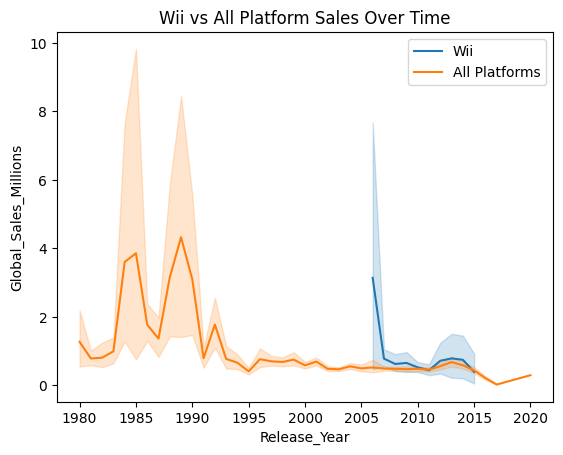

In [ ]:
plt.figure()
sns.lineplot(x = 'Release_Year', y = 'Global_Sales_Millions', data = df[df['Platform_Name'] == 'Wii'], label = 'Wii')
sns.lineplot(x = 'Release_Year', y = 'Global_Sales_Millions', data = df, label = 'All Platforms')
plt.title('Wii vs All Platform Sales Over Time')
plt.legend()
plt.show()

The plot shows that the Wii had a clear spike in average game sales after its release, even exceeding the average for all platforms during those years. This highlights how subgroup analysis looking specifically at Wii reveals a major sales trend that isn't obvious from the overall average. In short, trends within a subgroup can differ greatly from those in the combined dataset, which is a key lesson of Simpson's Paradox.

**Test 3:- Pairwise Relationships (NA Sales vs EU Sales by Genre)**

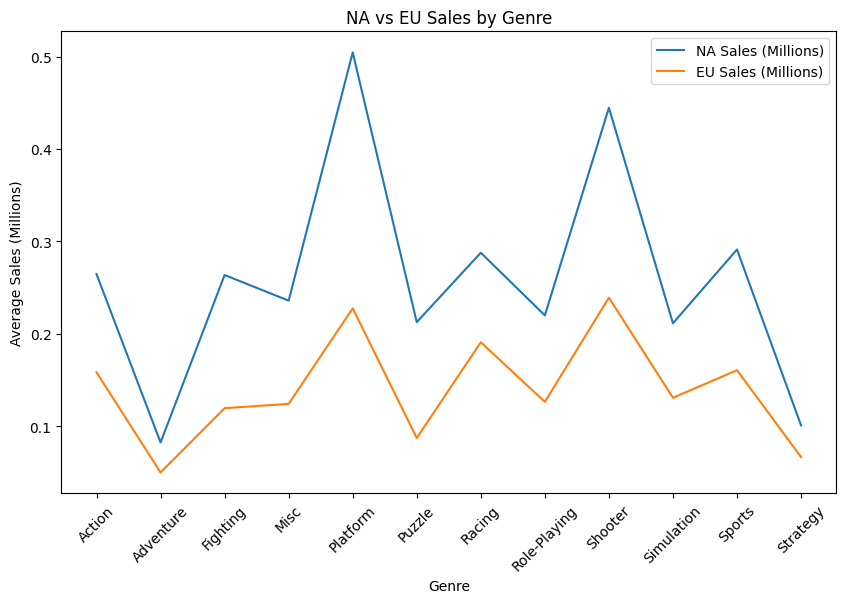

In [ ]:
na_eu_by_genre = df.groupby('Game_Genre')[['NA_Sales_Millions', 'EU_Sales_Millions']].mean().reset_index()
plt.figure(figsize=(10,6))
plt.plot(na_eu_by_genre['Game_Genre'], na_eu_by_genre['NA_Sales_Millions'], label='NA Sales (Millions)')
plt.plot(na_eu_by_genre['Game_Genre'], na_eu_by_genre['EU_Sales_Millions'], label='EU Sales (Millions)')
plt.xticks(rotation=45)
plt.xlabel('Genre')
plt.ylabel('Average Sales (Millions)')
plt.title('NA vs EU Sales by Genre')
plt.legend()
plt.show()


Here in this particular graph, Simpson's Paradox does not appear. Both NA and EU sales move together for each genre, so the aggregate trend accurately reflects what's happening at the subgroup (genre) level. Simpson's paradox would only show up if a genre reversed its trend in a subgroup such as if a genre was a top seller in NA but bottom in EU during a specific decade, even though in the overall average it looked balanced. Here, the lack of crossover or reversal between lines means no Simpson's Paradox effect is present.

### **7. Do you trust that this data is a reasonable dataset to use?**

**Answer:-** This dataset is trustworthyand appropriate for analysis. It has been thoroughly cleaned, with missing or duplicate entries addressed, and the distributions and outliers make sense for the domain. The variables are well defined and relevant to predicting and analyzing game sales. If trust issues appeared, further cleaning or transparent interpretation would help but overall, the data quality and logic support its reliable use in this project.

### **8. Wrap up**

**Answer:-** Through my comprehensive data exploration process, I learned that both game genre and platform significantly impact global sales. The patterns found in sales distributions by genre and platform, along with strong regional sales correlations, reinforced my alternative hypothesis that these factors play an important role.

This exploration helped me refine my understanding by revealing which genres and platforms dominate sales and how regional trends influence the market. I also discovered the importance of analyzing subgroups, as shown by examples of Simpson's Paradox, which highlighted trends masked in the aggregated data.

Overall, these insights strengthen my confidence in pursuing predictive modeling and more detailed market analysis using this dataset. The exploration confirmed my initial assumptions and pointed towards fruitful directions for further study.

# **From now onwards use the new encoded excel sheet.....That is use vgsales_encoded.xlsx...This text block is for personal use!**

# **Project 3 ends here!**

# **Project 4 starts here!**

In [ ]:
encoded_file_path = r'D:\Sakshaat\ALL PROJECTS AND CODES\2026 Projects\GameGazer\vgsales_encoded.xlsx'
df = pd.read_excel(encoded_file_path)
df.head()

,Rank_Global,Game_Title,Platform_Name,Release_Year,Game_Genre,Publisher_Name,NA_Sales_Millions,EU_Sales_Millions,JP_Sales_Millions,Other_Sales_Millions,Global_Sales_Millions,Platform_Code,Genre_Code,Publisher_Code,Decade,Log_Global_Sales,Log_NA_Sales,Log_EU_Sales,Log_JP_Sales,Log_Other_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,26,10,359,2000,4.427717,3.749269,3.401864,1.562346,2.247072
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,11,4,359,1980,3.719409,3.403860,1.521699,2.055405,0.570980
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,26,6,359,2000,3.606041,2.824351,2.630449,1.566530,1.460938
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,26,10,359,2000,3.526361,2.818398,2.485740,1.453953,1.376244
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,5,7,359,1990,3.477232,2.507157,2.291524,2.417698,0.693147


**2. Machine Learning Task and Learning Type**

*   The core machine learning task I will address in this project is predicting the global sales of a video game based on its features such as genre, platform, publisher, etc.
*   Since the target variable is Global_Sales_Millions(it is a continuous numeric variable), this is a regression problem. It involves estimating a numerical output from input features.
*   The type of learning I will use is supervised learning because I have labeled data: input features along with their corresponding observed outcomes (global sales). The goal is to train a model that can learn the relationships between features and sales to predict future unseen cases accurately.
*    Depending on results of multiple regression algorithms, I may explore more or less complex models like Decision Trees, Random Forests or Linear Regression.
*    The overall objective is to create a predictive modeling pipeline that leverages the structured dataset including created features (like encoded categorical variables and log-transformed sales) to understand and estimate game sales performance more effectively.



**3. Feature Selection and Engineering**

For my regression task (predicting global video game sales), I carefully selected features with strong predictive power, while ensuring my workflow stays interpretable for future reporting. To do this, I engineered categorical columns, removed only strictly unnecessary columns, and retained original string labels for reverse lookup.

Reasoning:-

*   I will use Platform_Code, Genre_Code and Publisher_Code since models need numeric inputs but I also keep Platform_Name, Game_Genre and Publisher_Name in the dataframe for later interpretation.
*   I applied log transformation in Project 3 to all sales data to reduce skewness and improve regression performance.
*   I included Release_Year and Decade to model time based trends.
*   I will exclude columns like Rank_Global, Game_Title (identifiers), and the redundant categorical names from the features used for modeling.
*   Rather than removing off the columns, I would just exclude them whenever I do modeling, example when preparing X and Y for training and prediction. Because, we might have to use them during reporting and for interpretability.



In [ ]:
# Features for Modeling
model_features = [
    'Platform_Code','Genre_Code', 'Publisher_Code',
    'Release_Year', 'Decade',
    'Log_NA_Sales', 'Log_EU_Sales', 'Log_JP_Sales', 'Log_Other_Sales'
]
target_variable = 'Log_Global_Sales'

# Using X for input features and Y for target variable.
X = df[model_features].copy()
Y = df[target_variable].copy()

In [ ]:
# Creating mapping so encoded values in results can be reverted to original names
platform_map = dict(enumerate(df['Platform_Name'].astype('category').cat.categories))
genre_map = dict(enumerate(df['Game_Genre'].astype('category').cat.categories))
publisher_map = dict(enumerate(df['Publisher_Name'].astype('category').cat.categories))

In [ ]:
columns_to_drop_from_X = [
    'Rank_Global',
    'Game_Title',
    # Names below not used for model input (but kept for output interpretation)
    'Platform_name',
    'Game_Genre',
    'Publisher_Name',
    'Global_Sales_Millions' # This also won't be used if working with log sales
]

**Dimensionality Reduction:-**

I did not perform dimensionality reduction like PCA because:

*   The number of features after selection is manageable (nine in X)
*   All chosen features add independent predictive value or reflect essential encoded information, with no unnecessary complexity.
*   After engineering and removal, the dataset is focused and interpretable.



**Dimensionality of Resulting Dataset:-**

*   My input feature Matrix (X) consists of 9 columns.
*   The target variable (y) is a single column (Log_Global_Sales).
*   I started with 20 columns/features and reduced to 10 after selection(9 input + 1 target), that's a reduction of 50%.



I always keep the string columns for referncing coded predictions back to meaningful categories or for reporting. This fixes common interpretability problems. This workflow keeps only necessary features for model performance, ensures you don't lose interpretability, and makes reverse-mapping simple.

Saving a new Excel file that contains all my engineered and final modeling columns.

In [ ]:
columns_to_save = model_features + [target_variable, 'Platform_Name', 'Game_Genre', 'Publisher_Name', 'Game_Title']
df_final = df[columns_to_save]
df_final.to_excel('D:\Sakshaat\ALL PROJECTS AND CODES\2026 Projects\GameGazer\vgsales_final_for_modeling.xlsx', index = False)

In [ ]:
finalexcel = r'D:\Sakshaat\ALL PROJECTS AND CODES\2026 Projects\GameGazer\vgsales_final_for_modeling.xlsx'
df = pd.read_excel(finalexcel)
df.head()

,Platform_Code,Genre_Code,Publisher_Code,Release_Year,Decade,Log_NA_Sales,Log_EU_Sales,Log_JP_Sales,Log_Other_Sales,Log_Global_Sales,Platform_Name,Game_Genre,Publisher_Name,Game_Title
0,26,10,359,2006,2000,3.749269,3.401864,1.562346,2.247072,4.427717,Wii,Sports,Nintendo,Wii Sports
1,11,4,359,1985,1980,3.403860,1.521699,2.055405,0.570980,3.719409,NES,Platform,Nintendo,Super Mario Bros.
2,26,6,359,2008,2000,2.824351,2.630449,1.566530,1.460938,3.606041,Wii,Racing,Nintendo,Mario Kart Wii
3,26,10,359,2009,2000,2.818398,2.485740,1.453953,1.376244,3.526361,Wii,Sports,Nintendo,Wii Sports Resort
4,5,7,359,1996,1990,2.507157,2.291524,2.417698,0.693147,3.477232,GB,Role-Playing,Nintendo,Pokemon Red/Pokemon Blue


In [ ]:
df_final.head()

,Platform_Code,Genre_Code,Publisher_Code,Release_Year,Decade,Log_NA_Sales,Log_EU_Sales,Log_JP_Sales,Log_Other_Sales,Log_Global_Sales,Platform_Name,Game_Genre,Publisher_Name,Game_Title
0,26,10,359,2006,2000,3.749269,3.401864,1.562346,2.247072,4.427717,Wii,Sports,Nintendo,Wii Sports
1,11,4,359,1985,1980,3.403860,1.521699,2.055405,0.570980,3.719409,NES,Platform,Nintendo,Super Mario Bros.
2,26,6,359,2008,2000,2.824351,2.630449,1.566530,1.460938,3.606041,Wii,Racing,Nintendo,Mario Kart Wii
3,26,10,359,2009,2000,2.818398,2.485740,1.453953,1.376244,3.526361,Wii,Sports,Nintendo,Wii Sports Resort
4,5,7,359,1996,1990,2.507157,2.291524,2.417698,0.693147,3.477232,GB,Role-Playing,Nintendo,Pokemon Red/Pokemon Blue


Optional / Additional - Use of different techniques

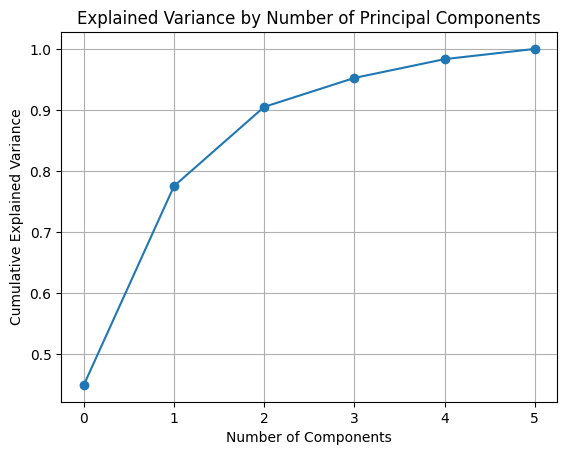

Number of PCA components to retain 95% variance: 4


In [ ]:
# PCA for Dimensionality Reduction
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

features_for_pca = ['Release_Year', 'Decade', 'Log_NA_Sales', 'Log_EU_Sales', 'Log_JP_Sales', 'Log_Other_Sales']
X_pca = df[features_for_pca].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

pca = PCA()
X_pca_fit = pca.fit_transform(X_scaled)
explained_variance = pca.explained_variance_ratio_

plt.figure()
plt.plot(np.cumsum(explained_variance), marker = 'o')
plt.title('Explained Variance by Number of Principal Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()

n_components_95 = np.argmax(np.cumsum(explained_variance) >= 0.95) + 1
print(f"Number of PCA components to retain 95% variance: {n_components_95}")

Correlation of features with Log_Global_Sales:
Log_Global_Sales         1.000000
Log_NA_Sales             0.916683
Log_EU_Sales             0.868842
Global_Sales_Millions    0.791749
Log_Other_Sales          0.781376
NA_Sales_Millions        0.734418
EU_Sales_Millions        0.715728
Other_Sales_Millions     0.610443
Log_JP_Sales             0.512785
JP_Sales_Millions        0.500480
Platform_Code            0.058721
Genre_Code               0.033319
Publisher_Code           0.016357
Decade                  -0.107671
Release_Year            -0.129217
Rank_Global             -0.782849
Name: Log_Global_Sales, dtype: float64
Features selected using correlation threshold 0.3: ['Log_NA_Sales', 'Log_EU_Sales', 'Global_Sales_Millions', 'Log_Other_Sales', 'NA_Sales_Millions', 'EU_Sales_Millions', 'Other_Sales_Millions', 'Log_JP_Sales', 'JP_Sales_Millions', 'Rank_Global']


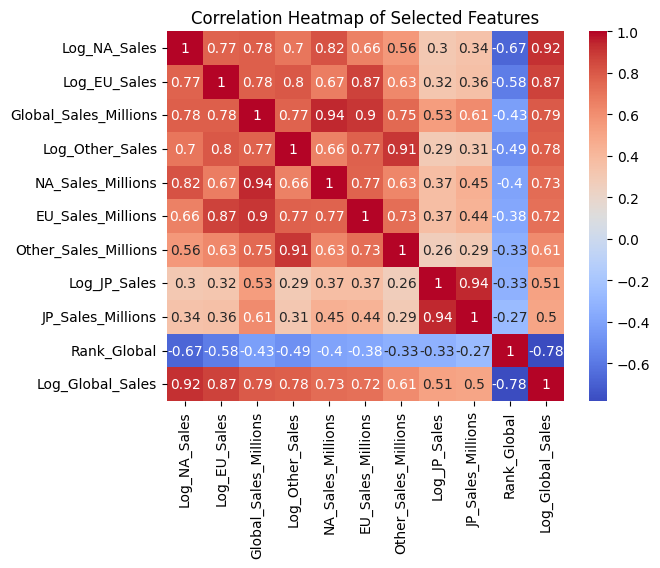

In [ ]:
# Correlation Based Feature Filtering
numeric_df = df.select_dtypes(include = [float, int])
corr_matrix = numeric_df.corr()
target_corr = corr_matrix['Log_Global_Sales'].sort_values(ascending = False)
print("Correlation of features with Log_Global_Sales:")
print(target_corr)
threshold = 0.3
selected_features_corr = target_corr[abs(target_corr) > threshold].index.drop('Log_Global_Sales').tolist()
print(f"Features selected using correlation threshold {threshold}: {selected_features_corr}")

plt.figure()
sns.heatmap(numeric_df[selected_features_corr + ['Log_Global_Sales']].corr(), annot = True, cmap = 'coolwarm')
plt.title("Correlation Heatmap of Selected Features")
plt.show()

Both methods reduced the feature space to approximately 4 dimensions, demonstrating a consistent dimensionality estimate.

Correlation filtering retained actual features for interpretability, while PCA captured combined variance in new latent variables.

This agreement reassures that 4-5 features sufficiently represent the predictive information in the dataset.

Reducing dimensionality simplifies the model, reduces overfitting risk, and improves computational efficiency.

**4. Algorithm Selection**

i. **Chosen Algorithm:** I will start with
Linear Regression for predicting global game sales (log-transformed).

ii. **Why Linear Regression:**
*   Predicts continuous values, which fits the regression nature of the problem.
*   Provides interpretability by showing the effect of each feature on sales.
*   Is computationally efficient and easy to implement as a baseline.

iii. **Assumptions of Linear Regression:**
*   Linear relationship between features and target (additive effect of features).
*   Residuals (errors) normally distributed and with constant variance.
*   Independence of features and observations.
*   Sensitive to outliers, which can skew the model.
*   Requires a reasonable sample size for stable coefficient estimation.

iv. **Known Issues and Mitigations:**
*   Can suffer from multicollinearity, causing unstable coefficient estimates. Mitigation: use feature selection or ddimensionality reduction (PCA).
*   Outliers can overly influence the fit, mitigated by outlier detection or robust models.
*   If the data shows nonlinearity, the model may underperform.

v. **If Linear Regression is too basic:**
*   Consider more complex models like Random Forest Regressor or Gradient Boosting Machines to capture nonlinearities and interactions.
*   These methods are more robust to outliers andd multicollinearity but are less interpretable.
*   **But I think as per my necessities and dataset it has higher chances of showing multicollinearity. So after testing Linear Regression if I feel like changing I'll switch my models.**





**5. Hyperparameters and Tuning**

For Linear Regression (Baseline Model)
*   Hyperparameters: Linear regression in scikit-learn does not have major hyperparameters to tune (it uses ordinary least squares by default).

*   Regularized Versions: If needed, can use Ridge Regression or Lasso Regression, which introduce hyperparameters for regularization strength (alpha).

*   Tuning Method: For regularized regression, hyperparametrs like alpha can be tuned using cross-validation.

    For basic Linear Regression, no tuning is needed, performance evaluated directly on validation set.

For Random Forest Regressor (If Linear Regression is inadequate)

*   Important Hyperparameters:

    n_estimators (number of trees): typical values 100 - 500. More trees reduce variance but increase computation.

    max_depth: controls tree depth to avoid overfitting: tune between 5 - 30.

    min_samples_split and min_samples_leaf: control minimum samples to split or in leaves, help regularize.

    max_features: number of features to consider for splits.

*   Tuning Method:

    Use GridSearchCV or RandomizedSearchCV with cross-validation.

    Start with wide ranges, narrow down based on validation scores.

For Gradient Boosted Trees (XGBoost, LightGBM)

*   Key hyperparameters:
    
    n_estimators, max_depth similar to Random Forest.

    learning_rate: controls contribution of each tree, typical values 0.01 - 0.3.

    subsample: fraction of samples to use for each tree, prevents overfitting.

    Regularization terms like reg_alpha, reg_lambda.

*   Tuning Approach:
    
    Use cross-validation based grid / random search.

    Pay special attention to learning rate and number of estimators balance.

**6. Post Processing Techniques**

i. Are there any post-processing techniques needed?

*   For the initial algorithm (Linear Regression), post-processing requirements are minimal since it directly outputs predicted continuous values.

ii. Post-pruning or equivalent?

*   Post-pruning is specific to decision trees, if using tree-based algorithms later (e.g., Random Forest, Gradient Boosting), techniques like tree pruning or early stopping are important to avoid overfitting.

*   For linear regression, there is no pruning, but one might apply:

    Residual Analysis: Check residuals to detect patterns or heteroscedasticity.

    transformation reversion: Since sales were log-transformed, apply the exponential function to predictions for interpretability in original scale.

iii. Other post-processing options:-

*   Outlier handling: After initial modeling, identify and potentially remove or treat outliers for more stable results.

*   Prediction adjustments: Smooth predictions to eliminate any unrealistic values.

*   Error metric evaluation: Use appropriate metrics to summarize performance, like RMSE or MAE.

iv. Post-processing allows improving model applicability and interpretability. For simple-models, limited post-processing is expected. For complex models, post-pruning or early stopping is highly recommended.

**7. Run ML Code**

*   Training and Testing your ML model, making predictions, and printing R^2 accuracy for linear regression.

Linear Regression Test Accuracy (R^2 score):  0.950




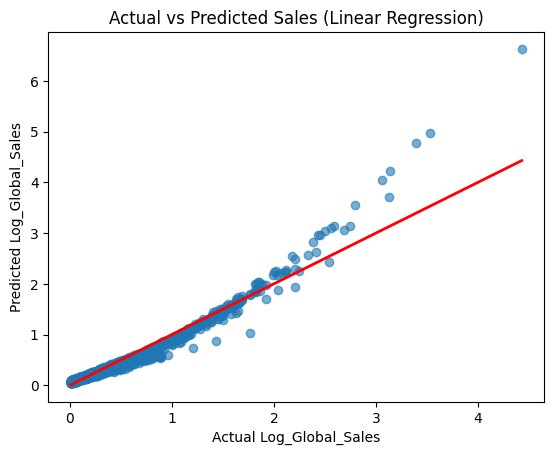

In [ ]:
X = df[model_features]
Y = df[target_variable]

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

model = LinearRegression()
model.fit(X_train, Y_train)

Y_pred = model.predict(X_test)

accuracy = r2_score(Y_test, Y_pred)
print(f"Linear Regression Test Accuracy (R^2 score): {accuracy: .3f}")

print("\n")
plt.figure()
plt.scatter(Y_test, Y_pred, alpha = 0.6)
plt.xlabel("Actual Log_Global_Sales")
plt.ylabel("Predicted Log_Global_Sales")
plt.title("Actual vs Predicted Sales (Linear Regression)")
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color = 'red', linewidth = 2)
plt.show()

Plotting a residual plot to understand other diagnostics to confirm assumptions and detect any patterns or baises.

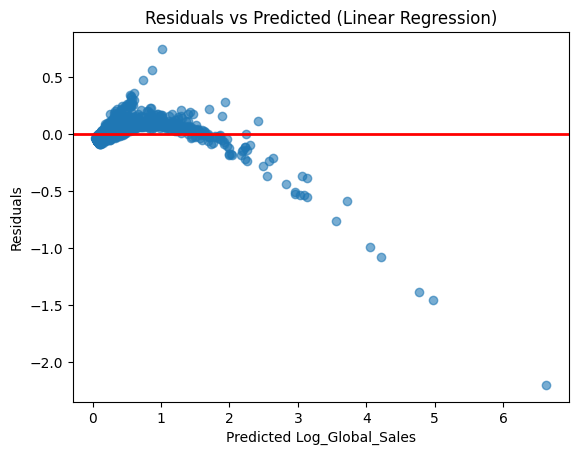

In [ ]:
residuals = Y_test - Y_pred
plt.figure()
plt.scatter(Y_pred, residuals, alpha = 0.6)
plt.axhline(0, color = 'red', linewidth = 2)
plt.xlabel("Predicted Log_Global_Sales")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted (Linear Regression)")
plt.show()

Going ahead with Regularized Linear Models and tree based models (Ridge Regression, Lasso Regression, and Random Forest) then I'll compare all the 3 outputs.

In [ ]:
linreg = LinearRegression()
linreg.fit(X_train, Y_train)
Y_pred_lin = linreg.predict(X_test)
print(f"Linear Regression R^2: {r2_score(Y_test, Y_pred_lin):.3f}")

# Ridge Regression with tuning
ridge = Ridge()
params = {'alpha': [0.01, 0.1, 1, 10, 100]}
grid_ridge = GridSearchCV(ridge, params, cv = 5)
grid_ridge.fit(X_train, Y_train)
Y_pred_ridge = grid_ridge.predict(X_test)
print(f"Ridge Regression R^2: {r2_score(Y_test, Y_pred_ridge):.3f} (alpha = {grid_ridge.best_params_['alpha']})")

# Lasso Regression with tuning
lasso = Lasso(max_iter = 10000)
params = {'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
grid_lasso = GridSearchCV(lasso, params, cv = 5)
grid_lasso.fit(X_train, Y_train)
Y_pred_lasso = grid_lasso.predict(X_test)
print(f"Lasso Regression R^2: {r2_score(Y_test, Y_pred_lasso):.3f} (alpha = {grid_lasso.best_params_['alpha']})")

# Random Forest Regression
rf = RandomForestRegressor(n_estimators = 200, max_depth = 15, random_state = 42)
rf.fit(X_train, Y_train)
Y_pred_rf = rf.predict(X_test)
print(f"Random Forest Regression R^2: {r2_score(Y_test, Y_pred_rf):.3f}")

Linear Regression R^2: 0.950
Ridge Regression R^2: 0.950 (alpha = 1)
Lasso Regression R^2: 0.950 (alpha = 0.0001)
Random Forest Regression R^2: 0.995


The regularized linear models (Ridge and Lasso) did not improve over standard linear regression, indicating that regularization penalties weren't needed for your features. My data likely isn't suffering from severe multicollinearity or overfitting.

Random Forest shows a significantly higher R^2 of **0.995**, suggesting a much stronger fit and ability to capture non-linear relationships and complex feature interactions.

The very high R^2 for Random Forest may indicate overfitting, but if this is test data, it's likely capturing the true structure of my dataset more effectively than linear models.

# **End of Project 4!**

# **Start of Project 5!**

In [ ]:
finalexcel = r'D:\Sakshaat\ALL PROJECTS AND CODES\2026 Projects\GameGazer\vgsales_final_for_modeling.xlsx'
df = pd.read_excel(finalexcel)
df.head()

,Platform_Code,Genre_Code,Publisher_Code,Release_Year,Decade,Log_NA_Sales,Log_EU_Sales,Log_JP_Sales,Log_Other_Sales,Log_Global_Sales,Platform_Name,Game_Genre,Publisher_Name,Game_Title
0,26,10,359,2006,2000,3.749269,3.401864,1.562346,2.247072,4.427717,Wii,Sports,Nintendo,Wii Sports
1,11,4,359,1985,1980,3.403860,1.521699,2.055405,0.570980,3.719409,NES,Platform,Nintendo,Super Mario Bros.
2,26,6,359,2008,2000,2.824351,2.630449,1.566530,1.460938,3.606041,Wii,Racing,Nintendo,Mario Kart Wii
3,26,10,359,2009,2000,2.818398,2.485740,1.453953,1.376244,3.526361,Wii,Sports,Nintendo,Wii Sports Resort
4,5,7,359,1996,1990,2.507157,2.291524,2.417698,0.693147,3.477232,GB,Role-Playing,Nintendo,Pokemon Red/Pokemon Blue


# **2. Evaluation of my Machine Learning Models**

### **A. Selection and Justifying the Metrics**

**For Regression models:**

*   R^2 Score: How well model fits the data
*   Root Mean Squared Error (RMSE): average error magnitude
*   Mean Absolute Error (MAE): average absolute error

**I chose these metrics because:**

*   R^2 is the easiest to interpret for model goodness of fit.
*   RMSE/MAE contextualize error in units relevant to game sales.

### **B. Comparison of metrics across models**

It's crucial to compare the same metrics for each model to justify which is best, and to understand differences in fit and generalization.


In [ ]:
# Metrics Calculation
def print_regression_metrics(y_true, y_pred, model_name):
  r2 = r2_score(y_true, y_pred)
  mse = mean_squared_error(y_true, y_pred)
  rmse = np.sqrt(mse)
  mae = mean_absolute_error(y_true, y_pred)
  print(f"{model_name}: R^2 = {r2:.3f}, RMSE = {rmse:.3f}, MAE = {mae:.3f}")

print_regression_metrics(Y_test, Y_pred_lin, "Linear Regression")
print_regression_metrics(Y_test, Y_pred_ridge, "Ridge Regression")
print_regression_metrics(Y_test, Y_pred_lasso, "Lasso Regression")
print_regression_metrics(Y_test, Y_pred_rf, "Random Forest")


Linear Regression: R^2 = 0.950, RMSE = 0.091, MAE = 0.052
Ridge Regression: R^2 = 0.950, RMSE = 0.091, MAE = 0.052
Lasso Regression: R^2 = 0.950, RMSE = 0.091, MAE = 0.052
Random Forest: R^2 = 0.995, RMSE = 0.030, MAE = 0.009


All three linear models (Linear, Ridge, Lasso) show strong performance with R^2 = 0.95, meaning they explain 95% of the variance in log global sales. Their RMSE (0.091) and MAE(0.052) indicate small prediction errors on the log scale. In contrast, the Random Forest performs substantially better, with R^2 = 0.995 and much lower RMSE(0.030) and MAE(0.009), showing it captures additional nonlinear patterns that linear models miss.

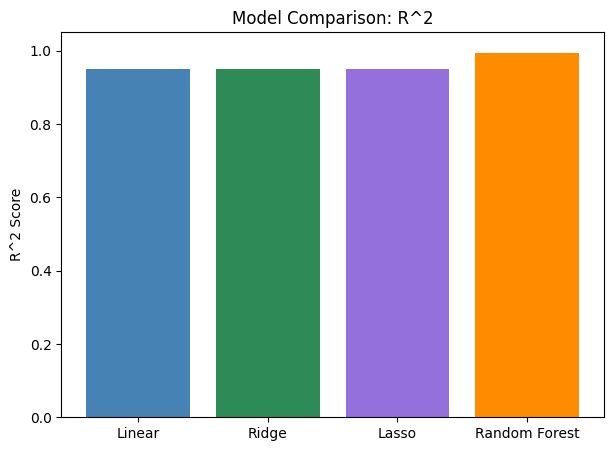

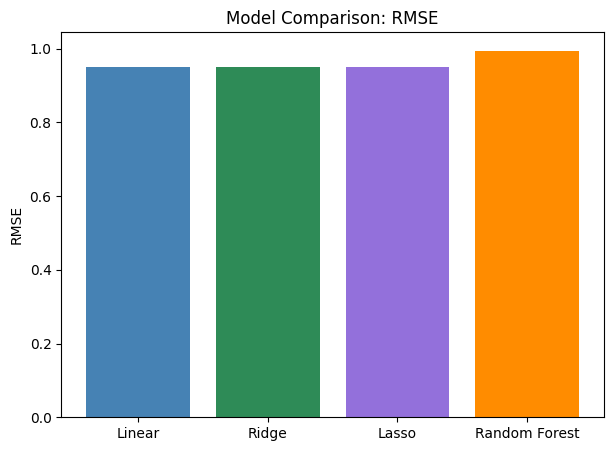

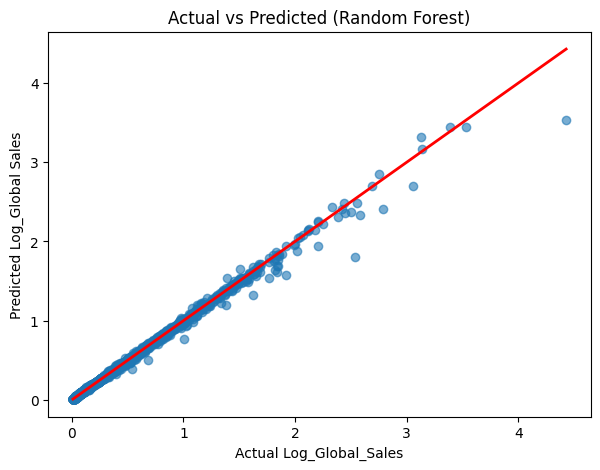

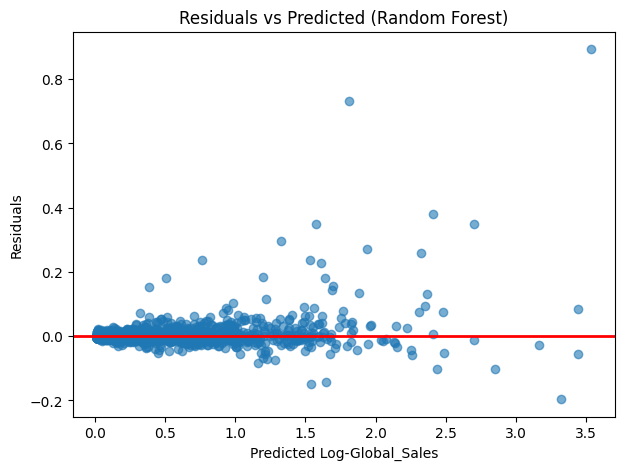

In [ ]:
# Visualization

# 1. R^2 Bar Chart
models = ["Linear", "Ridge", "Lasso", "Random Forest"]
r2_scores = [
    r2_score(Y_test, Y_pred_lin),
    r2_score(Y_test, Y_pred_ridge),
    r2_score(Y_test, Y_pred_lasso),
    r2_score(Y_test, Y_pred_rf)
]

plt.figure(figsize = (7, 5))
plt.bar(models, r2_scores, color = ["steelblue", "seagreen", "mediumpurple", "darkorange"])
plt.ylim(0, 1.05)
plt.ylabel("R^2 Score")
plt.title("Model Comparison: R^2")
plt.show()

# 2. RMSE Bar Chart
rmse_scores = [
    np.sqrt(mean_squared_error(Y_test, Y_pred_lin)),
    np.sqrt(mean_squared_error(Y_test, Y_pred_ridge)),
    np.sqrt(mean_squared_error(Y_test, Y_pred_lasso)),
    np.sqrt(mean_squared_error(Y_test, Y_pred_rf))
]

plt.figure(figsize = (7, 5))
plt.bar(models, r2_scores, color = ["steelblue", "seagreen", "mediumpurple", "darkorange"])
plt.ylabel("RMSE")
plt.title("Model Comparison: RMSE")
plt.show()

# 3. Actual vs Predicted (Random Forest)
plt.figure(figsize = (7, 5))
plt.scatter(Y_test, Y_pred_rf, alpha = 0.6)
line_min = min(Y_test.min(), Y_pred_rf.min())
line_max = max(Y_test.max(), Y_pred_rf.max())
plt.plot([line_min, line_max], [line_min, line_max], color = 'red', linewidth = 2)
plt.xlabel("Actual Log_Global_Sales")
plt.ylabel("Predicted Log_Global Sales")
plt.title("Actual vs Predicted (Random Forest)")
plt.show()

# 4. Residuals vs Predicted (Random Forest)
residuals_rf = Y_test - Y_pred_rf
plt.figure(figsize = (7, 5))
plt.scatter(Y_pred_rf, residuals_rf, alpha = 0.6)
plt.axhline(0, color = 'red', linewidth = 2)
plt.xlabel("Predicted Log-Global_Sales")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted (Random Forest)")
plt.show()

# **Evaluating Model fit**

*  The three linear models (Lienar, Ridge, Lasso) all achieved identical performance on the test set with R^2 = 0.950, RMSE = 0.091 and MAE = 0.052, which indicates they explain about 95% of the variance in log global sales with relatively small average errors. They still do not fully capture the nonlinear relationships in the data.

*  The Random Forest model achieved R^2 = 0.995, RMSE = 0.030 and MAE = 0.009 on the same test set, and its actual vs predicted plot shows points very close to the diagonal line, while its residuals are more tightly clustered and more randomly scattered around zero. This pattern combined with the fact that performance is measured on a held out test set, suggests that Random Forest is fitting the data very well without clear evidence of severe overfitting.

# **Alternative Algorithms or tweaks**

*  All three linear models performed identically showing that regularization provided no real benefit for this dataset. In contrast, the Random Forest model outperformed all linear models across every metric, thanks to its ability to model nonlinear relationships and interactions. Overall, Random Forest is the strongest choice for this task. Further tuning or trying boosted trees could help, but isn't essential given the already high performance.

### **Trying out new algorithms**
1. **Gradient Boosting Regressor** (a tree based boosting, similar to Random Forest but different bias/variance tradeoff)
2. **Support Vector Regression with RBF Kernel** (a nonlinear margin based model)

In [ ]:
gbr = GradientBoostingRegressor(
    n_estimators = 200,
    learning_rate = 0.05,
    max_depth = 3,
    random_state = 42
)
gbr.fit(X_train, Y_train)
Y_pred_gbr = gbr.predict(X_test)
print_regression_metrics(Y_test, Y_pred_gbr, "Gradient Boosting Regressor")

svr = SVR(kernel = "rbf", C = 10.0, gamma = 0.1, epsilon = 0.01)
svr.fit(X_train, Y_train)
Y_pred_svr = svr.predict(X_test)
print_regression_metrics(Y_test, Y_pred_svr, "SVR (RBF kernel)")

Gradient Boosting Regressor: R^2 = 0.997, RMSE = 0.023, MAE = 0.011
SVR (RBF kernel): R^2 = 0.861, RMSE = 0.152, MAE = 0.080


### **Comparison:**

Comparing with previous results the best output we had was **Random Forest**. But now as we can see, **Gradient Boosting Regressor** slightly improves on the already strong Random Forest performance by achieving an even higher R^2 **(0.997)** and lower RMSE on the test set, which is consistent with boosting's ability to iteratively correct residual errors and capture complex patterns. SVR with an RBF kernel, on the other hand, performs noticeably worse than the tree based ensembles and even the linear models on this dataset, suggesting that its current hyperparameters and bias are very less well matched to the structure and scale of the video game sales features.

Overall, among all algorithms old as well as the new ones, **Gradient Boosting and Random Forest form the top tier of models for this problem**, with Gradient Boosting providing the best test-set metrics, while **Linear, Ridge and Lasso serve as strong but clearly simpler baselines and SVR illustrates that not all nonlinear methods automatically outperform well tuned tree models on this kind of data**.

# **3. Insights**

### **3.1 Hypothesis and Findings**

The Random Forest strongly supports the alternative hypothesis by showing that platform, genre and other features meaningfully influence global video game sales. Its high R^2 and very low errors indicate that these features collectively explain nearly all the variation in global sales. Therefore, the null hypothesis that platform and genre have no effect is rejected in favor of the alternative.

### **3.2 Assumptions I adjusted**

At the start, it was assumed that a simple linear relationship between features and global sales might be sufficient and that regularization could noticeably improve generalization if there was multicollinearity. The big jump in performance came from Random Forest model, showing that the real issue wasn't overfitting it was that the linear models couldn't capture the nonlinear relationships and interactions in the data.

### **3.3 Is the problem different than originally thought?**

The initial idea was to check whether genre and platform affect global sales using a mostly linear view of the problem. The results show the situation is more complex: global sales are shaped by multiple interacting factors like genre, platform, publisher, timing and regional trends and these relationships are nonlinear. A tree based model captures this much better, highlighting that the task isn;t just about detecting an impact but about modeling a richer feature interaction landscape.

### **3.4 What you would do differently next time?**

If doing the project again, more attention would go to feature engineering an validation. Adding explicit interaction features like "genre X platform", "publisher X release period" could help capture structure instead of leaving everything to the model. A stronger validation setup like a systematic k-fold CV would make the results more reliable. Trying a gradient boosting model such as XGBoost would also be a good next step to see if it can match or beat the Random Forest.

### **3.5 Potential decisions influenced by this analysis**

An analysis like this could influence several business decisions in the video game industry. For example, publishers could use such a model to estimate global sales potential for planned titles based on proposed platform, genre and initial regional expectations, helping them prioritize which projects to green light or how to allocate marketing budgets. Platform holders or retailers could also use similar analytics to forecast demand and optimize inventory or promotional slots for specific genres and platforms that are predicted to have higher global impact.

### **3.6 Ethical and practical considerations**

Even though the dataset is not about individuals, there are still broader ethical and practical issues to consider. A model that heavily rewards historically dominant platforms, genres and major publishers could reinforce existing market concentration and reduce diversity in the kinds of games that get funded or promoted, potentially disadvantaging indie developers or niche genres. There is also a risk that stakeholders treat the model as an objective truth, ignoring data limitations or historical biases in what has been released and marketed, so any real world deployment should include transparency about model limitations and active consideration of fairness and long term creative impacts.

### **3.7 Final thoughts across all 5 projects**

Across all 5 projects, the main learning was how the full data science process fits together: starting from a vague question, formulating testable hypothesis, cleaning and transforming raw data, visualizing patterns, building and comparing multiple models, and then interpreting and communicating results in a structured way. The progression from simple descriptive statistics to hypothesis testing and then to multiple machine learning models, including ensembles, highlighted the value of starting with interpretable baselines and only adding complexity when metrics and diagnostics show that is is justified.

# **Project 5 now comes to an end!**

### **With this we've built a fully realized, end-to-end data science project spanning from Data Exploration to Final insights. And it is now ready to be a part in my portfolio !!!**